In [1]:
import pandas as pd
file_path = "/content/drive/MyDrive/clinical_trials_raw_patient2trial_conditions.csv"
df = pd.read_csv(file_path)

In [2]:
print(df.shape)
print(df.info())

(60337, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60337 entries, 0 to 60336
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   source_condition_query  60337 non-null  object
 1   nct_id                  60337 non-null  object
 2   title                   60337 non-null  object
 3   official_title          59551 non-null  object
 4   brief_summary           60337 non-null  object
 5   conditions              60336 non-null  object
 6   interventions           54276 non-null  object
 7   overall_status          60337 non-null  object
 8   study_type              60337 non-null  object
 9   phase                   23336 non-null  object
 10  sex                     60304 non-null  object
 11  minimum_age             57121 non-null  object
 12  maximum_age             28400 non-null  object
 13  healthy_volunteers      58857 non-null  object
 14  eligibility_criteria    60326 non-null  ob

In [4]:
df.head()

,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url
0,breast cancer,NCT03676114,Effect of Perioperative Low Dose Ketamine on P...,Effect of Perioperative Low Dose Ketamine on P...,Breast cancer patients often have perioperativ...,Breast Cancer,ketamine | Normal saline,UNKNOWN,INTERVENTIONAL,PHASE4,FEMALE,20 Years,65 Years,False,Inclusion Criteria:\n\n1. American Society of ...,https://clinicaltrials.gov/study/NCT03676114
1,breast cancer,NCT02941614,Implementing Systematic Distress Screening in ...,Implementing Systematic Distress Screening in ...,Many breast cancer patients experience psychol...,Breast Cancer,Distress screening,COMPLETED,OBSERVATIONAL,NaN,ALL,18 Years,NaN,False,Inclusion Criteria:\n\n* Newly diagnosed with ...,https://clinicaltrials.gov/study/NCT02941614
2,breast cancer,NCT04509063,Investigating Public Enthusiasm for Mammograph...,Investigating Public Enthusiasm for Mammograph...,"Based on an American study by Scherer et al., ...",Breast Neoplasm Female | Mammography Screening...,Information about hypothetical mammography scr...,COMPLETED,INTERVENTIONAL,NaN,FEMALE,44 Years,49 Years,True,Inclusion Criteria:\n\n* Residence: Central De...,https://clinicaltrials.gov/study/NCT04509063
3,breast cancer,NCT04327063,MIRs 04 : Interpectoral Nerve Block With Ropiv...,A Double-blind Randomized Trial of Interpector...,Compare the effect of ropivacaine versus place...,Malignant Neoplasm of Breast,Saline | Ropivacaine,COMPLETED,INTERVENTIONAL,PHASE3,FEMALE,18 Years,85 Years,False,Inclusion Criteria:\n\n1. Women with non-metas...,https://clinicaltrials.gov/study/NCT04327063
4,breast cancer,NCT06778863,A Study of CLSP-1025 in Adult Patients With So...,GUARDIAN-101: A Phase 1 Dose Escalation and Ex...,Phase 1 dose escalation and expansion study of...,Advanced Solid Tumor | Unresectable Solid Tumo...,CLSP-1025,RECRUITING,INTERVENTIONAL,PHASE1,ALL,18 Years,NaN,False,Key Inclusion Criteria:\n\n* Patients must be ...,https://clinicaltrials.gov/study/NCT06778863


In [5]:
df = df.dropna(subset=['brief_summary', 'source_condition_query'])

In [6]:
df = df.drop_duplicates().reset_index(drop=True)

In [7]:
!pip install pandas nltk scikit-learn

In [8]:
import re
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

In [11]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [12]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = word_tokenize(text)
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]
    return " ".join(cleaned_tokens)
df['cleaned_summary'] = df['brief_summary'].apply(clean_text)

In [13]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf_vectorizer.fit_transform(df['cleaned_summary'])
print("TF-IDF Matrix Shape:", X_tfidf.shape)

TF-IDF Matrix Shape: (60337, 5000)


In [14]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df['source_condition_query'])

print("Encoded target vector shape:", y_encoded.shape)
print("Mapping classes to integers:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Encoded target vector shape: (60337,)
Mapping classes to integers: {'anxiety': np.int64(0), 'breast cancer': np.int64(1), 'chronic obstructive pulmonary disease': np.int64(2), 'covid-19': np.int64(3), 'glaucoma': np.int64(4), 'rheumatoid arthritis': np.int64(5), 'sickle cell anemia': np.int64(6), 'type 2 diabetes': np.int64(7)}


In [15]:
!pip install matplotlib seaborn

Statistical Summary of Disease Categories
source_condition_query
breast cancer                            16301
type 2 diabetes                          11467
covid-19                                 10153
anxiety                                   9286
chronic obstructive pulmonary disease     6181
rheumatoid arthritis                      3637
glaucoma                                  2173
sickle cell anemia                        1139
Name: count, dtype: int64


/tmp/ipykernel_846/3612628515.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.values, y=category_counts.index, palette="viridis")


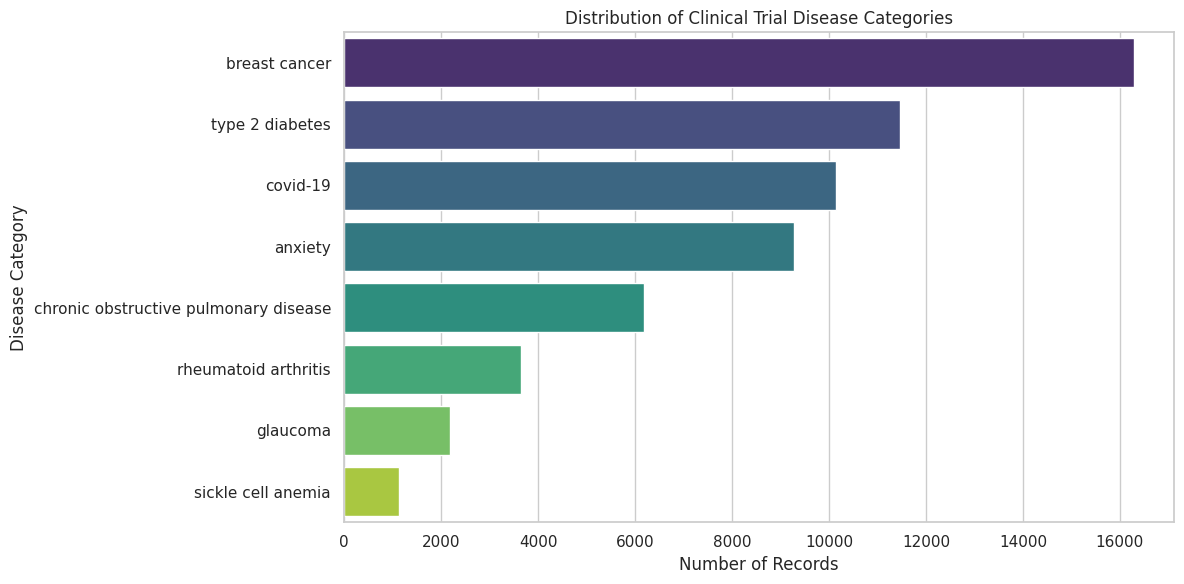

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
print("Statistical Summary of Disease Categories")
category_counts = df['source_condition_query'].value_counts()
print(category_counts)

plt.figure()
sns.barplot(x=category_counts.values, y=category_counts.index, palette="viridis")
plt.title("Distribution of Clinical Trial Disease Categories")
plt.xlabel("Number of Records")
plt.ylabel("Disease Category")
plt.tight_layout()
plt.show()


/tmp/ipykernel_846/2597914961.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequency', y='Keyword', data=top_keywords, palette="rocket")


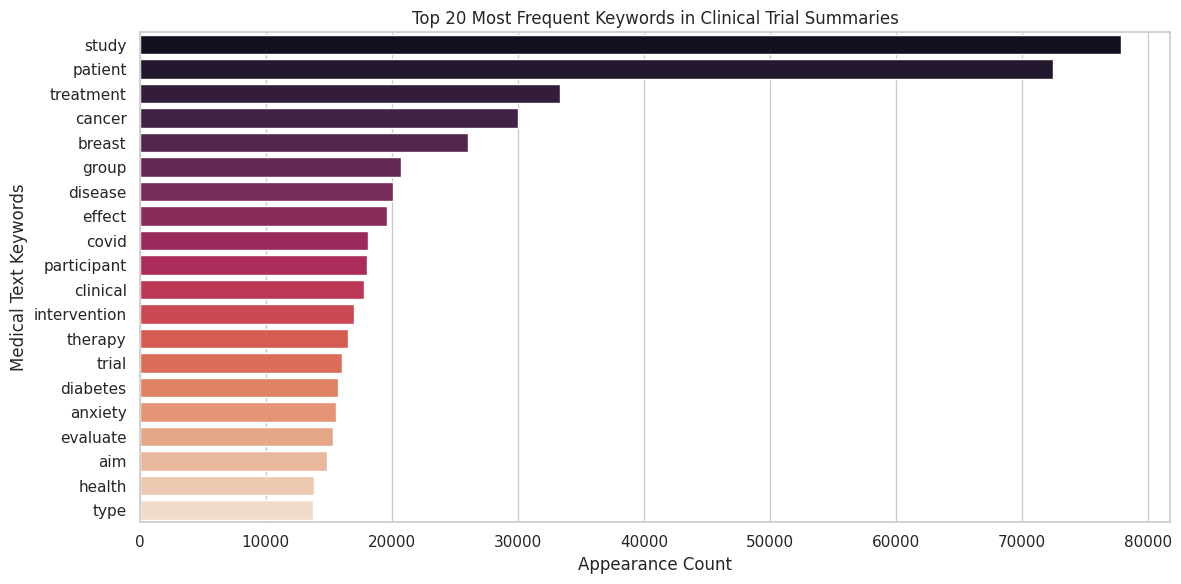

In [17]:
all_words = " ".join(df['cleaned_summary'].astype(str)).split()
word_frequencies = Counter(all_words)
top_keywords = pd.DataFrame(word_frequencies.most_common(20), columns=['Keyword', 'Frequency'])
plt.figure()
sns.barplot(x='Frequency', y='Keyword', data=top_keywords, palette="rocket")
plt.title("Top 20 Most Frequent Keywords in Clinical Trial Summaries")
plt.xlabel("Appearance Count")
plt.ylabel("Medical Text Keywords")
plt.tight_layout()
plt.show()


 Summary Word Count Statistical Descriptions
count    60337.000000
mean        61.942009
std         56.430568
min          2.000000
25%         23.000000
50%         42.000000
75%         81.000000
max        486.000000
Name: summary_word_count, dtype: float64


/tmp/ipykernel_846/3528274262.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='summary_word_count', y='source_condition_query', data=df, palette="mako")


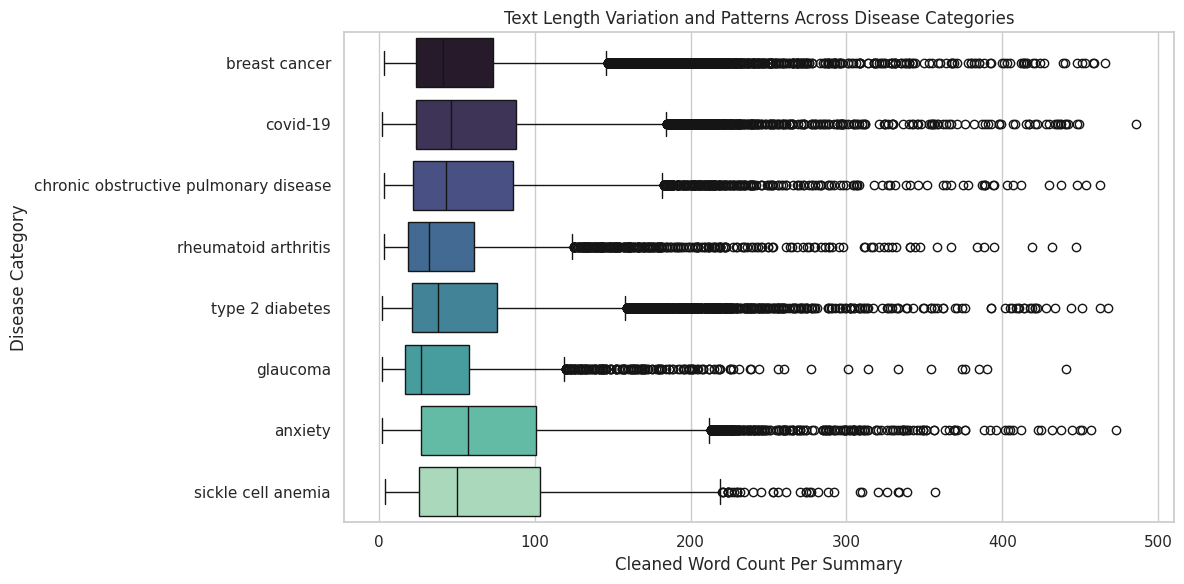

In [18]:
df['summary_word_count'] = df['cleaned_summary'].apply(lambda x: len(str(x).split()))

print("\n Summary Word Count Statistical Descriptions")
print(df['summary_word_count'].describe())
plt.figure()
sns.boxplot(x='summary_word_count', y='source_condition_query', data=df, palette="mako")
plt.title("Text Length Variation and Patterns Across Disease Categories")
plt.xlabel("Cleaned Word Count Per Summary")
plt.ylabel("Disease Category")
plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [20]:
X = df['cleaned_summary'].astype(str)
y = df['source_condition_query']
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

In [21]:
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [22]:
models = {
    "Naive Bayes (MultinomialNB)": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}
performance_metrics = {}
best_model_name = ""
best_accuracy = 0.0
best_preds = None

print("Performance Classification Reports")
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred)
    performance_metrics[name] = acc

    print(f"\n=================== {name} ===================")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Performance Classification Reports

=================== Naive Bayes (MultinomialNB) ===================
Accuracy: 0.8891
                                       precision    recall  f1-score   support

                              anxiety       0.76      0.93      0.84      1857
                        breast cancer       0.94      0.91      0.93      3260
chronic obstructive pulmonary disease       0.92      0.80      0.86      1236
                             covid-19       0.90      0.87      0.89      2031
                             glaucoma       0.97      0.86      0.91       435
                 rheumatoid arthritis       0.95      0.80      0.87       727
                   sickle cell anemia       0.97      0.64      0.77       228
                      type 2 diabetes       0.89      0.94      0.91      2294

                             accuracy                           0.89     12068
                            macro avg       0.91      0.85      0.87     12068
        

/tmp/ipykernel_846/1921339556.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


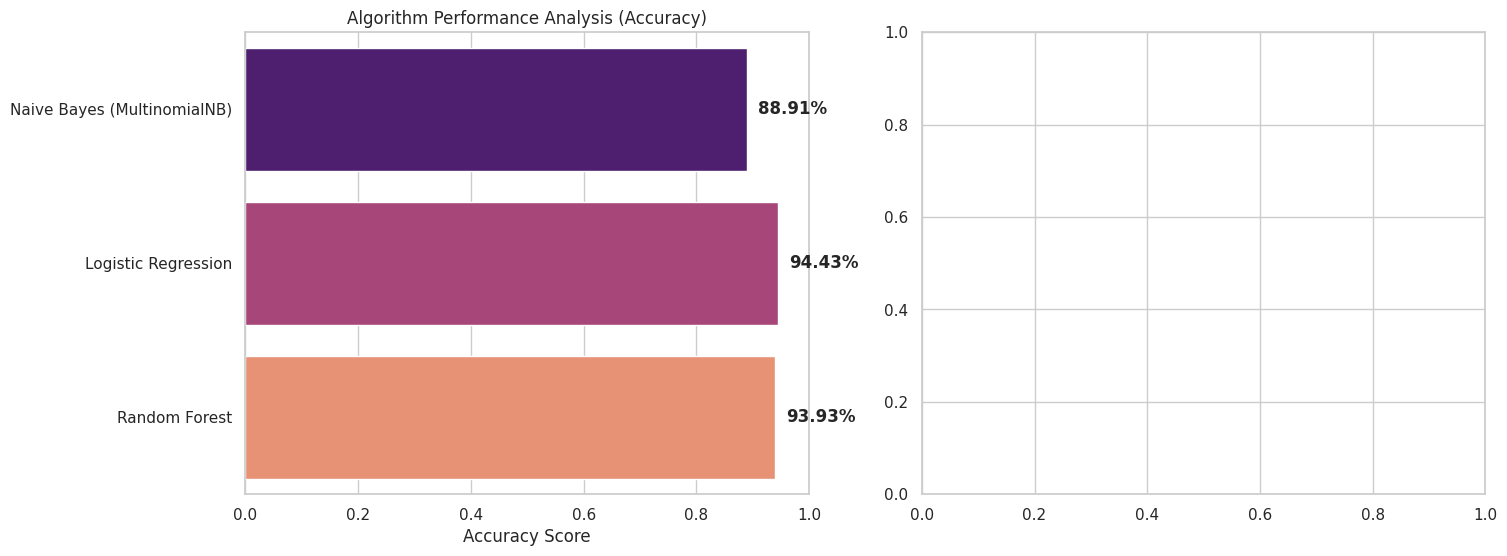

In [30]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(
    x=list(performance_metrics.values()),
    y=list(performance_metrics.keys()),
    ax=axes[0],
    palette="magma"
)
axes[0].set_title("Algorithm Performance Analysis (Accuracy)")
axes[0].set_xlabel("Accuracy Score")
axes[0].set_xlim(0, 1.0)
for i, val in enumerate(performance_metrics.values()):
    axes[0].text(val + 0.02, i, f"{val:.2%}", va='center', fontweight='bold')

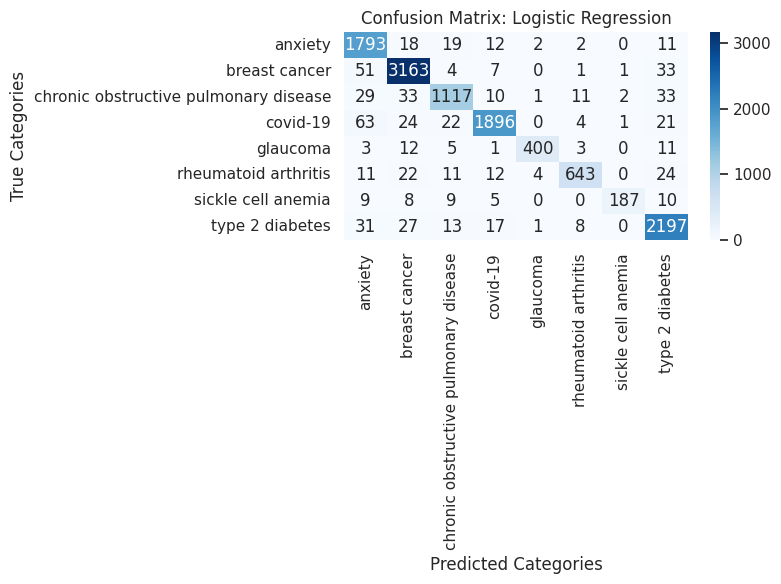

In [31]:
log_reg_preds = models["Logistic Regression"].predict(X_test_tfidf)
cm = confusion_matrix(y_test, log_reg_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Confusion Matrix: Logistic Regression")
plt.xlabel("Predicted Categories")
plt.ylabel("True Categories")
plt.tight_layout()
plt.show()

In [32]:
def predict_disease_category(raw_text_input, model_object, vectorizer_object, encoder_object):
  cleaned_input = clean_text(raw_text_input) # Calls your pre-existing clean_text function
  vectorized_input = vectorizer_object.transform([cleaned_input])
  numeric_prediction = model_object.predict(vectorized_input)[0]
  probabilities = model_object.predict_proba(vectorized_input)[0]
  confidence_score = np.max(probabilities)
  string_prediction = encoder_object.inverse_transform([numeric_prediction])[0]
  return string_prediction, confidence_score

In [33]:
best_classifier = models["Logistic Regression"]
print("Disease Prediction System Active")

Disease Prediction System Active


In [34]:
sample_clinical_summary_1 = (
    "A randomized phase II study evaluating the safety and efficacy of targeted "
    "chemotherapy combinations in patients diagnosed with metastatic invasive ductal carcinoma."
)

predicted_label_1, confidence_1 = predict_disease_category(
    sample_clinical_summary_1, best_classifier, tfidf_vectorizer, label_encoder
)

print(f"\n[Test Case 1]")
print(f"Input Text : {sample_clinical_summary_1[:80]}...")
print(f"Predicted  : {predicted_label_1} (Confidence: {confidence_1:.2%})")


sample_clinical_summary_2 = (
    "Clinical evaluation of fasting blood glucose control metrics and long-term "
    "insulin sensitivity transformations in adult subjects experiencing chronic metabolic insulin resistance."
)

predicted_label_2, confidence_2 = predict_disease_category(
    sample_clinical_summary_2, best_classifier, tfidf_vectorizer, label_encoder
)

print(f"\n[Test Case 2]")
print(f"Input Text : {sample_clinical_summary_2[:80]}...")
print(f"Predicted  : {predicted_label_2} (Confidence: {confidence_2:.2%})")


[Test Case 1]
Input Text : A randomized phase II study evaluating the safety and efficacy of targeted chemo...
Predicted  : breast cancer (Confidence: 97.39%)

[Test Case 2]
Input Text : Clinical evaluation of fasting blood glucose control metrics and long-term insul...
Predicted  : type 2 diabetes (Confidence: 99.22%)


In [40]:
import pickle
with open('best_classifier.pkl', 'wb') as f:
    pickle.dump(models["Logistic Regression"], f)

with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf_vectorizer, f)

with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

print("All live model assets exported successfully!")

All live model assets exported successfully!


In [35]:
!pip install streamlit plotly pyngrok --quiet

In [43]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import re
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(page_title="Clinical Trial Classifier", layout="wide")
st.title("NLP-Based Disease Classification System")

#TRAINED model
@st.cache_resource
def load_ml_assets():
    with open('best_classifier.pkl', 'rb') as f:
        model = pickle.load(f)
    with open('tfidf_vectorizer.pkl', 'rb') as f:
        vectorizer = pickle.load(f)
    with open('label_encoder.pkl', 'rb') as f:
        encoder = pickle.load(f)
    return model, vectorizer, encoder

try:
    model, vectorizer, encoder = load_ml_assets()
except FileNotFoundError:
    st.error("Model asset files missing! Run the export cell in your notebook first.")

def deploy_clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

user_input = st.text_area("Paste the Clinical Trial Brief Summary text below:")

if st.button("Run Disease Classification Analysis", type="primary"):
    if user_input.strip() == "":
        st.warning("Please insert valid clinical text.")
    else:
        cleaned_text = deploy_clean_text(user_input)
        vectorized_text = vectorizer.transform([cleaned_text])

        real_probabilities = model.predict_proba(vectorized_text)[0]
        best_class_idx = np.argmax(real_probabilities)

        predicted_class = encoder.classes_[best_class_idx]
        confidence_score = real_probabilities[best_class_idx]

        # Display Results
        st.success("### Prediction Engine Analysis Complete!")
        col1, col2 = st.columns(2)
        with col1:
            st.metric(label="Predicted Disease Category", value=str(predicted_class))
        with col2:
            st.metric(label="Model Prediction Confidence", value=f"{confidence_score:.2%}")

        # matching probability bar chart
        fig, ax = plt.subplots(figsize=(8, 4))
        sns.barplot(x=real_probabilities, y=list(encoder.classes_), ax=ax, palette="viridis")
        ax.set_xlim(0, 1.0)
        for i, val in enumerate(real_probabilities):
            ax.text(val + 0.01, i, f"{val:.1%}", va='center', fontweight='bold')
        st.pyplot(fig)

Overwriting app.py


In [37]:
!pkill streamlit
!pip install pyngrok --quiet
import os
from google.colab import userdata
from pyngrok import ngrok
token = userdata.get('NGROK_AUTH_TOKEN')
ngrok.set_auth_token(token)
!nohup streamlit run app.py --server.port 8501 &
public_url = ngrok.connect(8501)
print(f'link:{public_url}')

nohup: appending output to 'nohup.out'
link:NgrokTunnel: "https://dodge-gigabyte-debtless.ngrok-free.dev" -> "http://localhost:8501"
